# Fitting Gaia astrometry and radial velocities of a single-planet system

This notebook
1. simulates Gaia DR5 epoch astrometry and three radial-velocity (RV) datasets of a star with one giant planet,
2. fits the RVs alone (best fit, plot, MCMC and corner plot), and
3. fits the astrometry and RVs jointly (best fit, plots, MCMC and corner plot).

It needs `gaiamockplus`, `emcee` and `corner`. The two MCMCs take about 3 minutes in total.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
import gaiamockplus as gmp
from gaiamockplus import gaiamock

%config InlineBackend.figure_format = 'retina'

c_funcs = gaiamock.read_in_C_functions()  # compiled functions used by gaiamock's routines
rng = np.random.default_rng(6)            # random numbers for the simulation (reproducible)
M_JUP = 1/1047.57                         # Jupiter mass in Msun

## 1. Simulate the astrometry and the RVs

The system is that of notebook 01, but with a 3 $M_\mathrm{J}$ planet, so that the astrometric signal is smaller. The RVs come from three instruments, each with its own systemic velocity (zero point) and formal uncertainties. The simulated RVs also include 3 m/s of jitter (extra scatter, e.g. from stellar activity), added in quadrature to the formal uncertainties, which do not include it. RVs are in km/s, and RV times are in years relative to the same reference epoch as the astrometry. The RV signal follows from the same orbit as the astrometry ($\omega$ is the argument of periastron of the star's orbit in both).

In [2]:
# the star and the planet: as in notebook 01, with a 3 Jupiter-mass planet
m_star = 0.8               # Msun
parallax = 10.0            # mas
phot_g_mean_mag = 11.1     # G magnitude of a 0.8 Msun main-sequence star at 100 pc
ra, dec = 25.0, -13.0      # deg
pmra, pmdec = 12.0, 30.0   # mas/yr
planet = dict(period=365.25*4.0**1.5/np.sqrt(m_star), Tp=500.0, ecc=0.2,
              Omega=np.radians(110.0), inc=np.radians(60.0), w=np.radians(50.0), m_planet=3*M_JUP)

# Gaia astrometry
ast_data = gmp.predict_astrometry_planets(ra=ra, dec=dec, parallax=parallax, pmra=pmra, pmdec=pmdec, m_star=m_star,
                                          planets=[planet], phot_g_mean_mag=phot_g_mean_mag, data_release='dr5',
                                          c_funcs=c_funcs, rng=rng)
t_ast_yr, psi, plx_factor, ast_obs, ast_err = ast_data

# three RV datasets: number of RVs, formal uncertainty (km/s), and time range (yr, relative to the reference epoch)
n_rv = [5, 7, 10]
rv_err_set = [0.007, 0.010, 0.010]
time_ranges = [(-10, -4), (-5, 1), (0, 7)]
gamma = np.array([-12.405, -12.380, -12.420])  # systemic velocity of each dataset (km/s)
jitter = 0.003                                 # km/s

t_rvs_yr = np.concatenate([np.sort(rng.uniform(*r, n)) for r, n in zip(time_ranges, n_rv)])
rv_dataset = np.repeat([0, 1, 2], n_rv)        # the dataset of each RV
rv_err = np.repeat(rv_err_set, n_rv)           # formal uncertainties
rv = (gmp.rv_planets_model(t_rvs_yr, m_star, [planet], gamma, c_funcs, rv_dataset=rv_dataset)
      + np.sqrt(rv_err**2 + jitter**2)*rng.normal(0, 1, len(t_rvs_yr)))
rv_data = (t_rvs_yr, rv, rv_err)

a0_true, K_true = gmp.get_planet_a0_mas(m_star, [planet], parallax)[0], gmp.get_planet_K_kms(m_star, [planet])[0]
print(f'astrometry: {len(t_ast_yr)} transits, a0 = {a0_true:.3f} mas, median uncertainty {np.median(ast_err):.3f} mas')
print(f'RVs: {len(rv)} in {len(n_rv)} datasets, K = {1e3*K_true:.1f} m/s')

astrometry: 170 transits, a0 = 0.143 mas, median uncertainty 0.047 mas
RVs: 22 in 3 datasets, K = 42.0 m/s


## 2. Fit the RVs alone

`fit_rv_planets` uses the same search over $(P, \phi_p, e)$ as `fit_astrometry_planets`; for each trial, the linear parameters (the systemic velocity of each dataset, and $K\cos\omega$, $K\sin\omega$) are solved exactly. The jitter of each dataset is fitted by maximum likelihood (`fit_jitter=True`, the default). RVs alone constrain $m_p \sin i$, but not $i$ or $\Omega$.

In [3]:
res_rv = gmp.fit_rv_planets(*rv_data, rv_dataset=rv_dataset, n_planets=1, m_star=m_star)
fit_rv = res_rv['planets'][0]

rows = [('P [yr]', planet['period']/365.25, fit_rv['period']/365.25, fit_rv['sig_period']/365.25),
        ('e', planet['ecc'], fit_rv['ecc'], fit_rv['sig_ecc']),
        ('K [m/s]', 1e3*K_true, 1e3*fit_rv['K'], 1e3*fit_rv['sig_K']),
        ('w [deg]', 50.0, np.degrees(fit_rv['w']), np.degrees(fit_rv['sig_w'])),
        ('m_p sin i [M_Jup]', planet['m_planet']*np.sin(planet['inc'])/M_JUP, fit_rv['m_sini']/M_JUP, fit_rv['sig_m_sini']/M_JUP)]
print(f"{'':18s} {'true':>8s} {'fit':>16s}")
for label, true, value, sigma in rows:
    print(f'{label:18s} {true:8.3f} {value:8.3f} +/- {sigma:.3f}')
print('jitter [m/s]: true 3 for each dataset; fit', np.round(1e3*res_rv['jitter'], 1))

                       true              fit
P [yr]                8.944    8.703 +/- 0.339
e                     0.200    0.216 +/- 0.065
K [m/s]              42.045   46.214 +/- 5.192
w [deg]              50.000   35.139 +/- 26.028
m_p sin i [M_Jup]     2.598    2.820 +/- 0.297
jitter [m/s]: true 3 for each dataset; fit [0. 0. 0.]


With only 5 to 10 RVs per dataset and 7 to 10 m/s uncertainties, a 3 m/s jitter cannot be detected: the maximum-likelihood jitter is 0 for each dataset. The MCMC below gives its posterior (upper limits).

The plot shows the RVs with each dataset's systemic velocity subtracted (error bars: formal uncertainty and fitted jitter in quadrature), the best-fit orbit, and the residuals. The same function is used for the joint fit below.

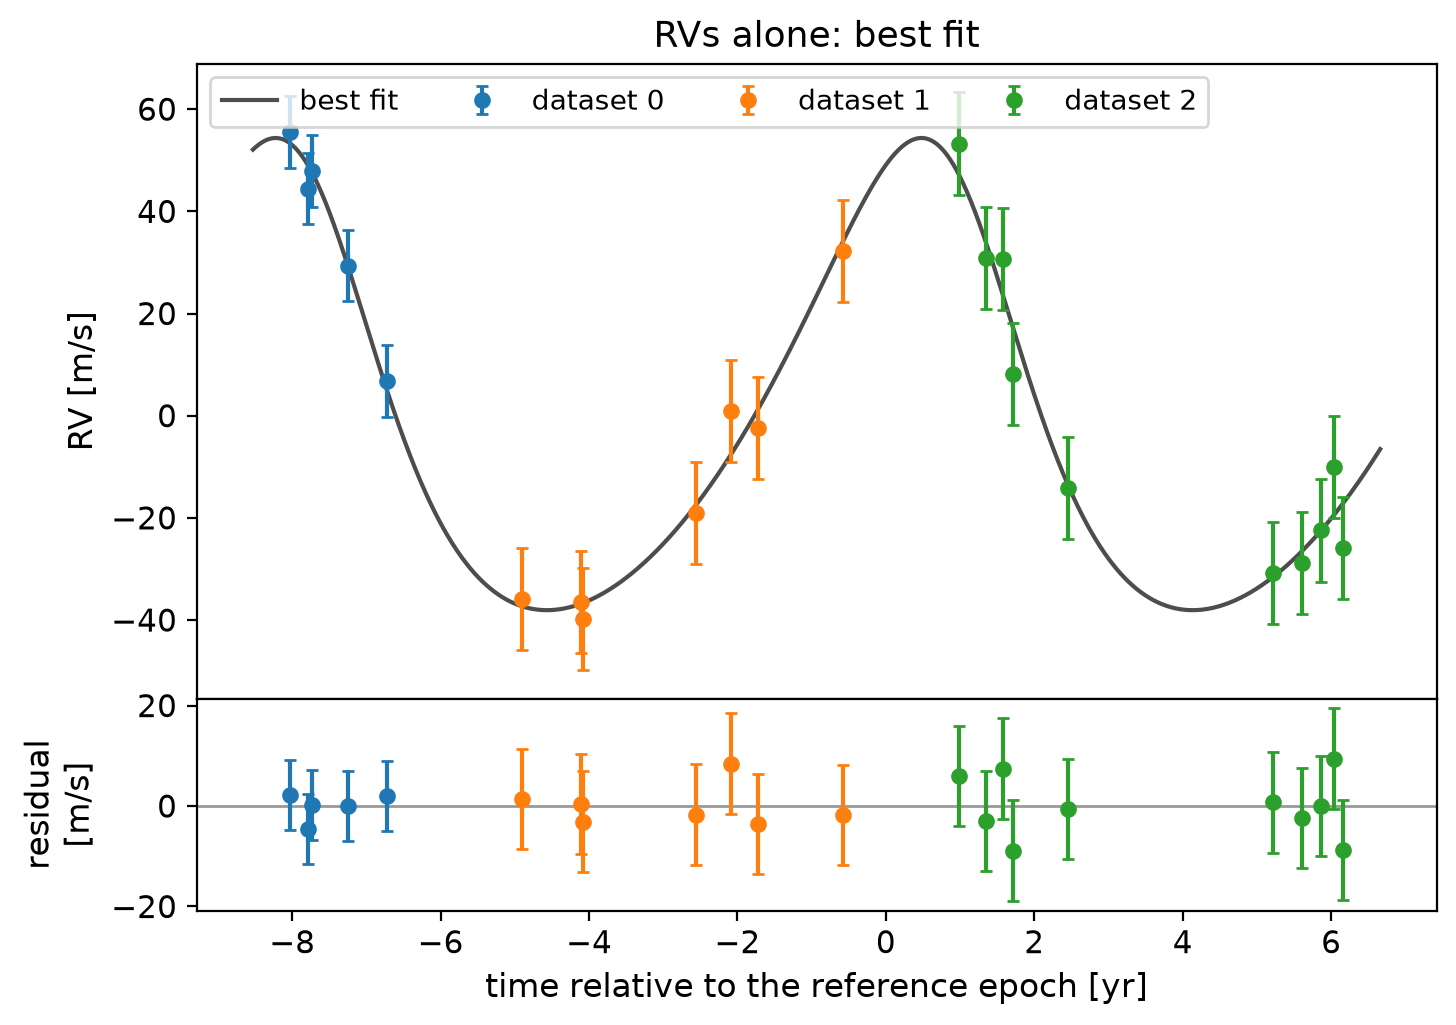

In [4]:
def plot_rvs(res, title):
    '''RVs minus each dataset's systemic velocity, the best-fit RV curve, and the residuals, for a fit result.'''
    t_grid = np.linspace(t_rvs_yr.min() - 0.5, t_rvs_yr.max() + 0.5, 2000)
    curve = gmp.rv_planets_model(t_grid, m_star, res['model_planets'], 0.0, c_funcs)
    model = gmp.rv_planets_model(t_rvs_yr, m_star, res['model_planets'], res['gamma'], c_funcs, rv_dataset=rv_dataset)
    err = np.sqrt(rv_err**2 + res['jitter'][rv_dataset]**2)
    fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1], hspace=0))
    axes[0].plot(t_grid, 1e3*curve, color='0.3', lw=1.5, zorder=0, label='best fit')
    for k in range(len(n_rv)):
        on = rv_dataset == k
        axes[0].errorbar(t_rvs_yr[on], 1e3*(rv[on] - res['gamma'][k]), 1e3*err[on], fmt='o', ms=5, capsize=2, label=f'dataset {k}')
        axes[1].errorbar(t_rvs_yr[on], 1e3*(rv[on] - model[on]), 1e3*err[on], fmt='o', ms=5, capsize=2)
    axes[1].axhline(0, color='0.6', lw=1, zorder=0)
    axes[0].set_ylabel('RV [m/s]', fontsize=12)
    axes[1].set_ylabel('residual\n[m/s]', fontsize=12)
    axes[1].set_xlabel('time relative to the reference epoch [yr]', fontsize=12)
    axes[0].set_title(title, fontsize=13)
    axes[0].legend(fontsize=10, ncol=4, loc='upper left')
    for ax in axes:
        ax.tick_params(labelsize=11)
    plt.show()

plot_rvs(res_rv, 'RVs alone: best fit')

### MCMC for the RVs

`log_likelihood_rv_planets` takes a parameter vector ordered like `res_rv['theta']` (a systemic velocity per dataset, then $P$, $e$, $\phi_p$, $K\cos\omega$, $K\sin\omega$), followed by the jitter of each dataset, and includes the $\ln(2\pi\sigma^2)$ terms that make the jitter a free parameter. `initial_walkers` appends the fitted jitter to the starting point. The priors are uniform, with the jitter between 0 and 50 m/s. With these sparse RVs, the posterior has long tails (e.g. to longer periods and higher eccentricities); the corner plots show the central 99% of each parameter.

In [5]:

def log_prior_rv(theta):
    P, e, jit = theta[3], theta[4], theta[8:]
    if 10 < P < 1e4 and 0 <= e < 1 and np.all((0 <= jit) & (jit < 0.05)):
        return 0.0
    return -np.inf

def log_prob_rv(theta):
    lp = log_prior_rv(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + gmp.log_likelihood_rv_planets(theta, *rv_data, rv_dataset=rv_dataset)

nwalkers, nsteps = 32, 55000
p0 = gmp.initial_walkers(res_rv, nwalkers, log_prob=log_prior_rv, rng=rng)
np.random.seed(6)  # emcee draws its moves from numpy's global random state
sampler_rv = emcee.EnsembleSampler(nwalkers, p0.shape[1], log_prob_rv)
sampler_rv.run_mcmc(p0, nsteps, progress=True);

autocorrelation times [steps]: gamma_0 569, gamma_1 594, gamma_2 522, period_0 754, ecc_0 847, phi_p_0 966, K_cos_w_0 1047, K_sin_w_0 770, jitter_0 578, jitter_1 457, jitter_2 431
chain length / longest autocorrelation time = 53
3040 samples


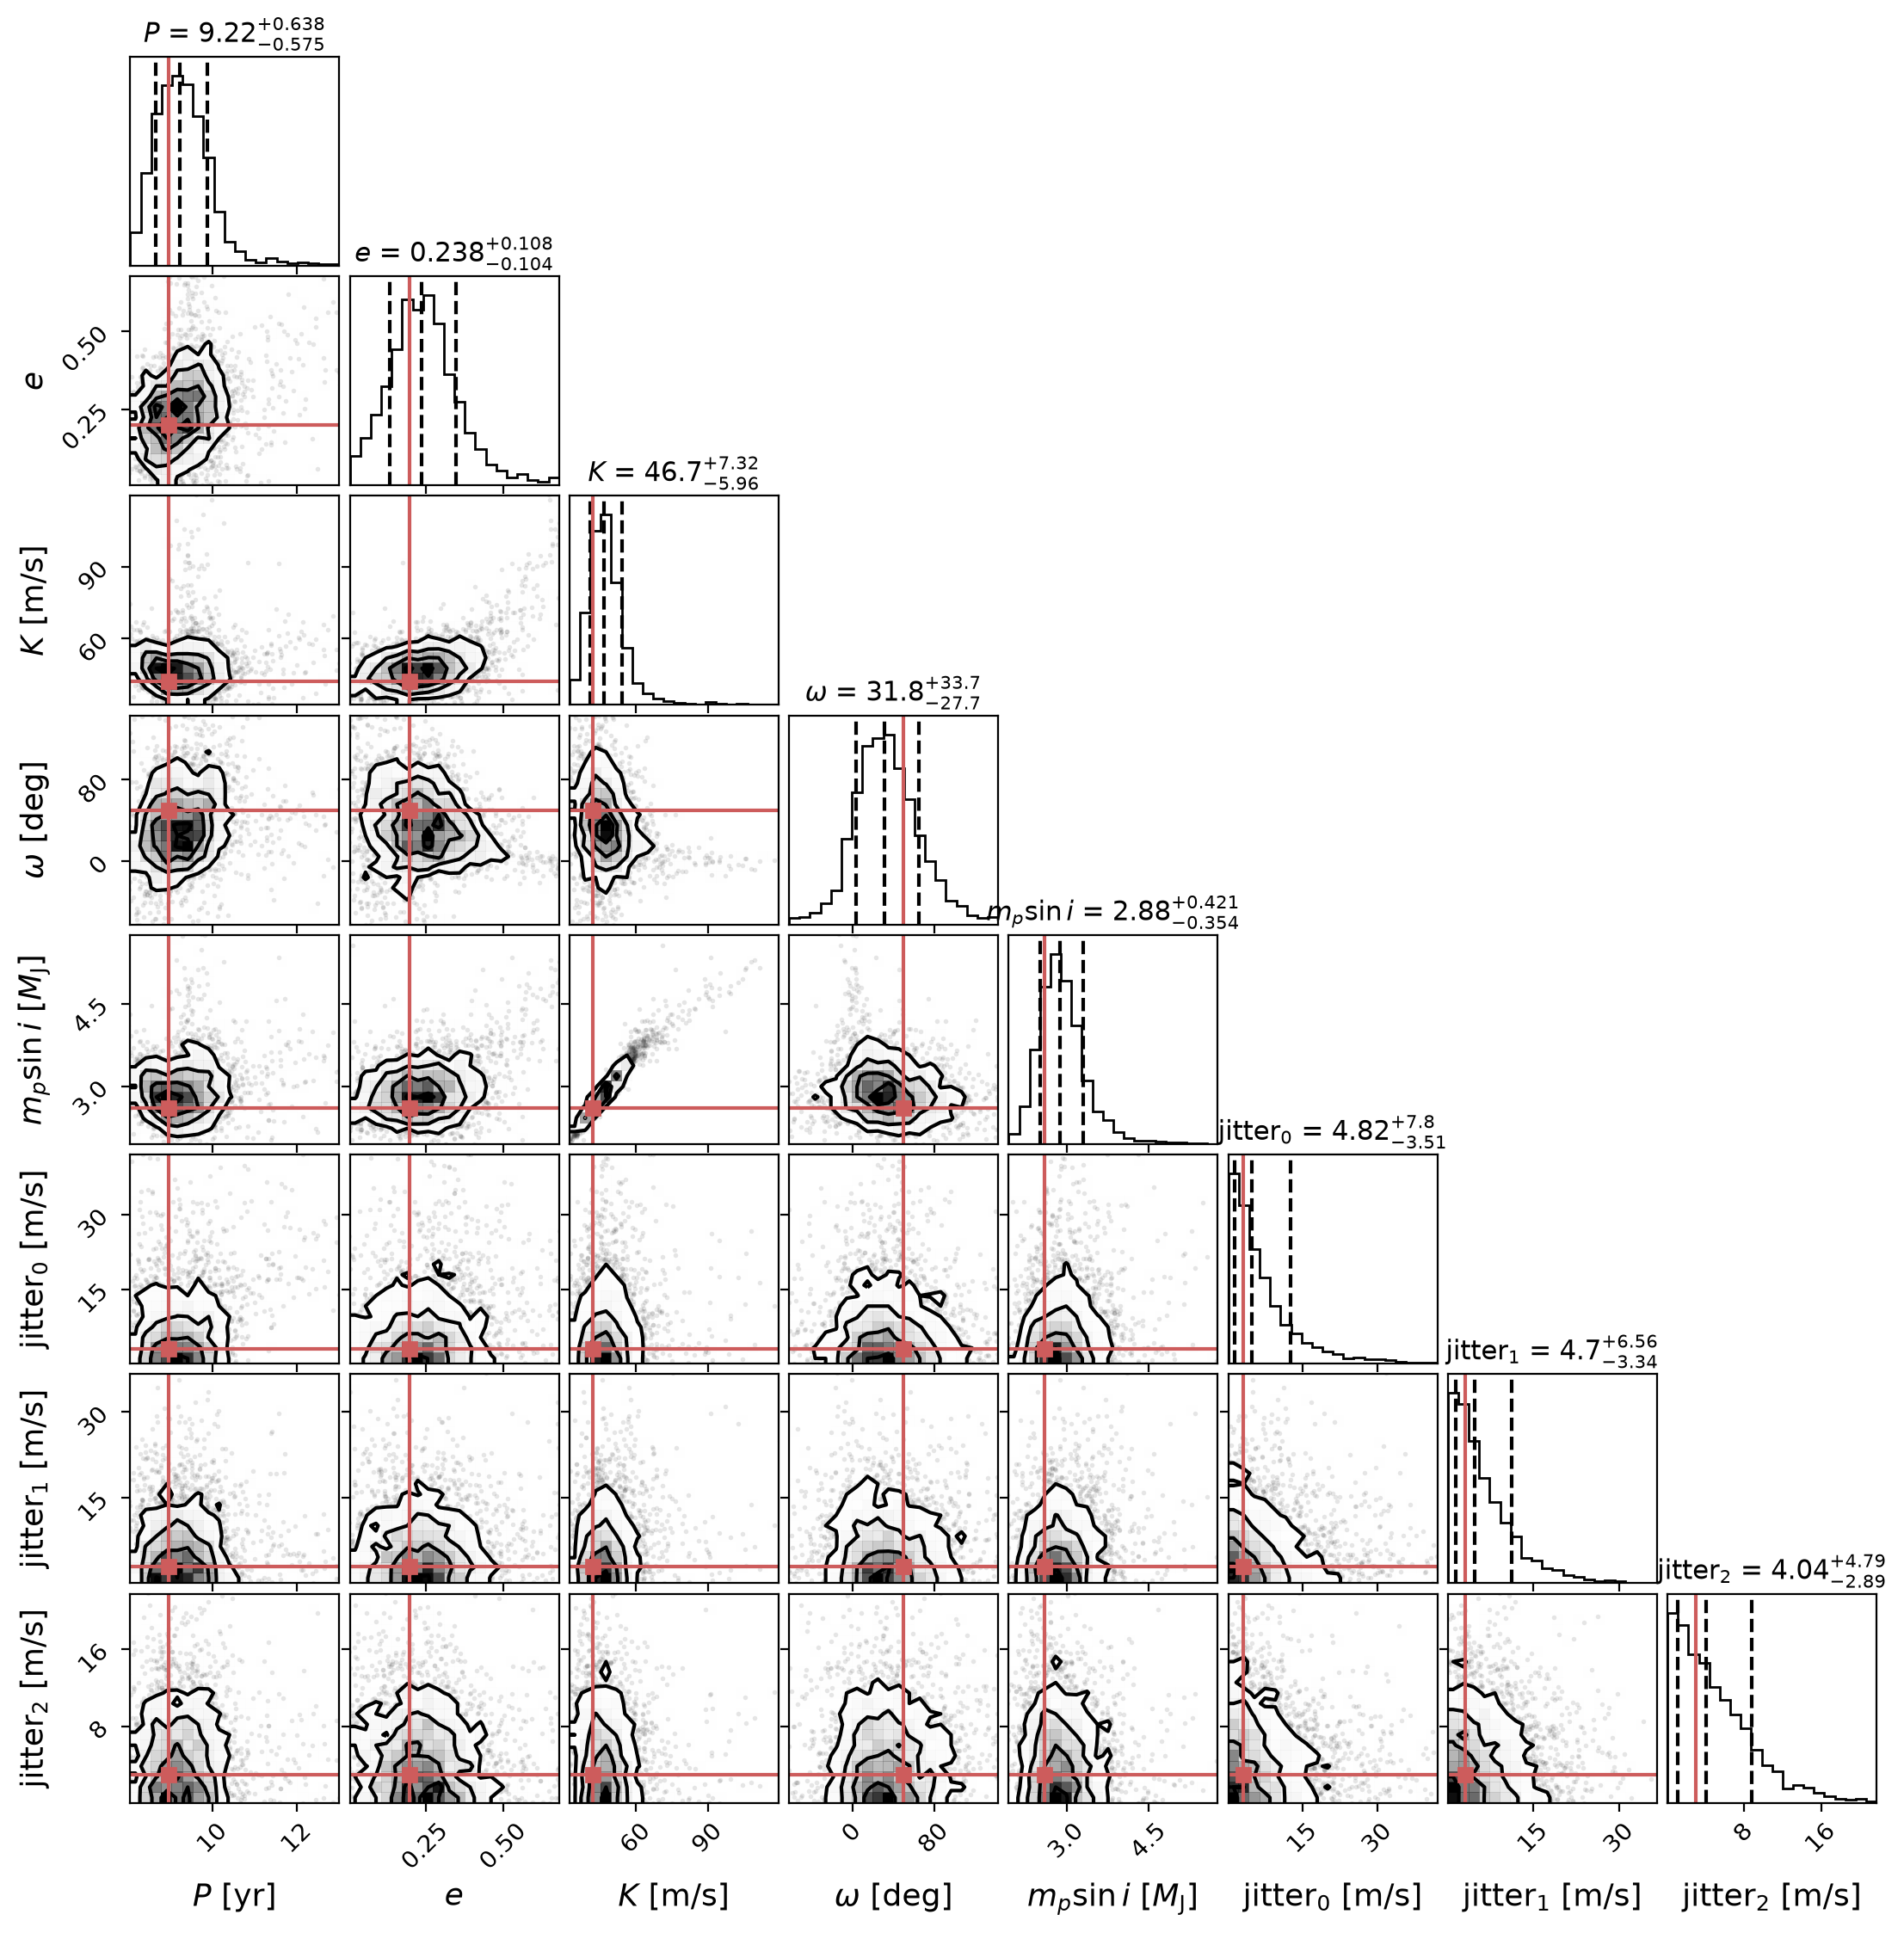

In [6]:
# convergence: the chain should be much longer than the autocorrelation time (tol=0: estimate it whatever the chain length)
names_rv = res_rv['theta_names'] + ['jitter_0', 'jitter_1', 'jitter_2']
tau = sampler_rv.get_autocorr_time(tol=0)
print('autocorrelation times [steps]:', ', '.join(f'{n} {t:.0f}' for n, t in zip(names_rv, tau)))
print(f'chain length / longest autocorrelation time = {nsteps/tau.max():.0f}')
burn, thin = int(5*tau.max()), int(tau.max()/2)  # discard the burn-in (5 autocorrelation times) and thin the chain
samples_rv = sampler_rv.get_chain(discard=burn, thin=thin, flat=True)
print(f'{len(samples_rv)} samples')

# physical parameters for each sample: K, w, and m sin i (the inverse of the RV semi-amplitude)
P_s, e_s, h_s, c_s, jit_s = samples_rv[:, 3], samples_rv[:, 4], samples_rv[:, 6], samples_rv[:, 7], samples_rv[:, 8:]
K_s = np.hypot(h_s, c_s)
w_s = fit_rv['w'] + np.angle(np.exp(1j*(np.arctan2(c_s, h_s) - fit_rv['w'])))  # w is an angle: keep it continuous around the best fit
msini_s = gmp.get_planet_m_sini(K_s, P_s, e_s, m_star)

corner_rv = np.column_stack([P_s/365.25, e_s, 1e3*K_s, np.degrees(w_s), msini_s/M_JUP, 1e3*jit_s])
labels = [r'$P$ [yr]', r'$e$', r'$K$ [m/s]', r'$\omega$ [deg]', r'$m_p\sin i$ [$M_\mathrm{J}$]'] + [f'jitter$_{k}$ [m/s]' for k in range(3)]
titles = [r'$P$', r'$e$', r'$K$', r'$\omega$', r'$m_p\sin i$'] + [f'jitter$_{k}$' for k in range(3)]
truths = [planet['period']/365.25, planet['ecc'], 1e3*K_true, 50.0, planet['m_planet']*np.sin(planet['inc'])/M_JUP, 3.0, 3.0, 3.0]
fig = corner.corner(corner_rv, range=[0.99]*corner_rv.shape[1], labels=labels, titles=titles, truths=truths, truth_color='indianred', quantiles=[0.16, 0.5, 0.84],
                    show_titles=True, title_fmt='.3g', max_n_ticks=3, labelpad=0.08, label_kwargs=dict(fontsize=13), title_kwargs=dict(fontsize=11))
fig.set_size_inches(11, 11)
plt.show()

## 3. Fit the astrometry and the RVs jointly

`fit_astrometry_and_rv_planets` first searches over $(P, \phi_p, e)$ with both datasets (the orbit shared, the astrometric and RV amplitudes solved separately), then fits the full physical model: the RV semi-amplitude follows from the astrometric orbit ($K$ from $a_0$, $\varpi$, $i$, $P$ and $e$), with a systemic velocity and a jitter for each RV dataset. Together, the astrometry and the RVs give the planet's true mass and resolve the $(\Omega, \omega) \to (\Omega + \pi, \omega + \pi)$ ambiguity of astrometry alone. `consistency_delta` measures how much the joint model is worse than the separate amplitudes (about $\chi^2$ with 2 degrees of freedom if the astrometry and RVs agree).

In [7]:
res_joint = gmp.fit_astrometry_and_rv_planets(*ast_data, *rv_data, rv_dataset=rv_dataset, n_planets=1, m_star=m_star)
fit = res_joint['planets'][0]

rows = [('parallax [mas]', parallax, res_joint['parallax'], res_joint['sig_parallax']),
        ('P [yr]', planet['period']/365.25, fit['period']/365.25, fit['sig_period']/365.25),
        ('e', planet['ecc'], fit['ecc'], fit['sig_ecc']),
        ('a0 [mas]', a0_true, fit['a0_mas'], fit['sig_a0_mas']),
        ('m_p [M_Jup]', planet['m_planet']/M_JUP, fit['m_planet']/M_JUP, fit['sig_m_planet']/M_JUP),
        ('inc [deg]', 60.0, np.degrees(fit['inc']), np.degrees(fit['sig_inc'])),
        ('w [deg]', 50.0, np.degrees(fit['w']), np.degrees(fit['sig_w'])),
        ('Omega [deg]', 110.0, np.degrees(fit['Omega']), np.degrees(fit['sig_Omega']))]
print(f"{'':18s} {'true':>8s} {'fit':>16s}")
for label, true, value, sigma in rows:
    print(f'{label:18s} {true:8.3f} {value:8.3f} +/- {sigma:.3f}')
print('jitter [m/s]: fit', np.round(1e3*res_joint['jitter'], 1))
print(f"consistency_delta = {res_joint['consistency_delta']:.1f}")

                       true              fit
parallax [mas]       10.000    9.996 +/- 0.008
P [yr]                8.944    8.885 +/- 0.256
e                     0.200    0.195 +/- 0.054
a0 [mas]              0.143    0.151 +/- 0.008
m_p [M_Jup]           3.000    3.177 +/- 0.175
inc [deg]            60.000   57.252 +/- 3.736
w [deg]              50.000   44.903 +/- 22.966
Omega [deg]         110.000  107.461 +/- 4.651
jitter [m/s]: fit [0. 0. 0.]
consistency_delta = 1.7


The best-fit orbit on the sky (as in notebook 01, with the Thiele-Innes elements computed from the fitted Campbell elements) and the best-fit RVs:

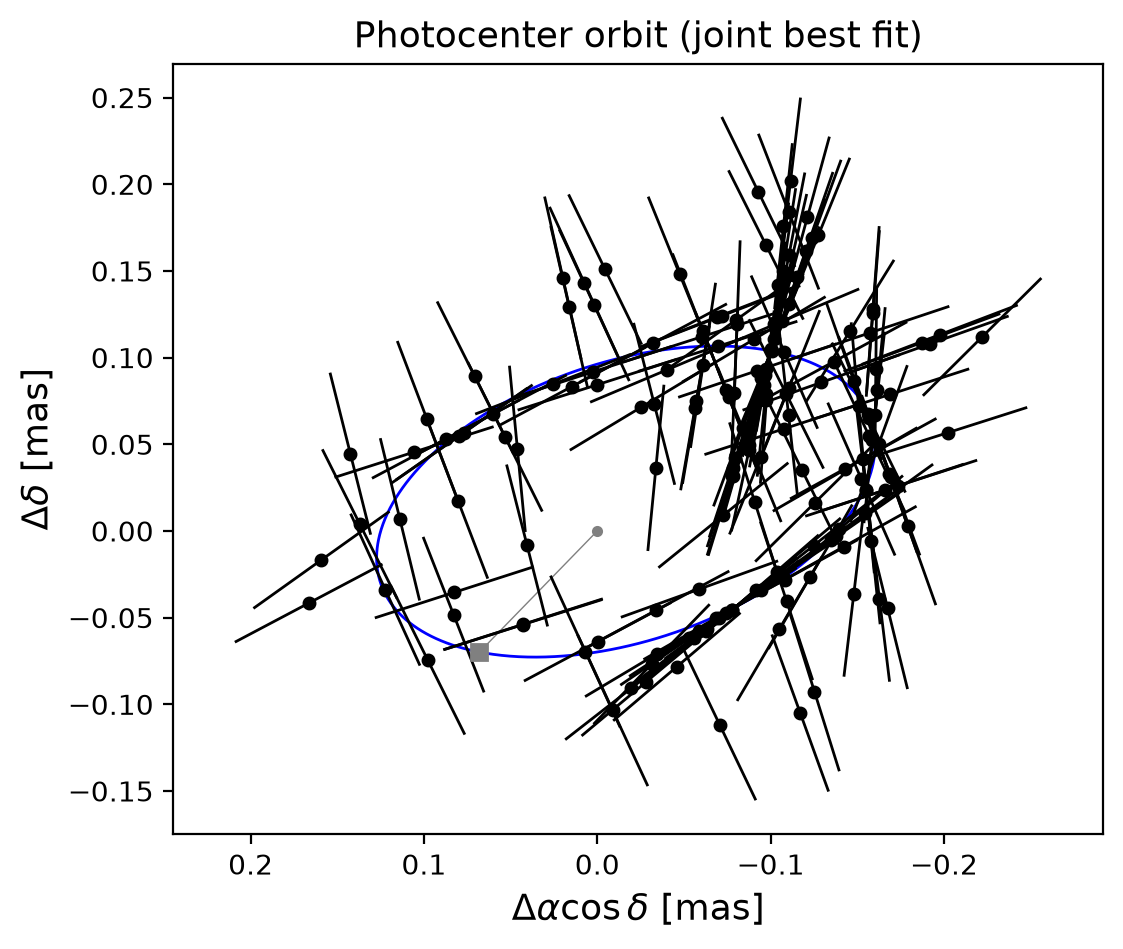

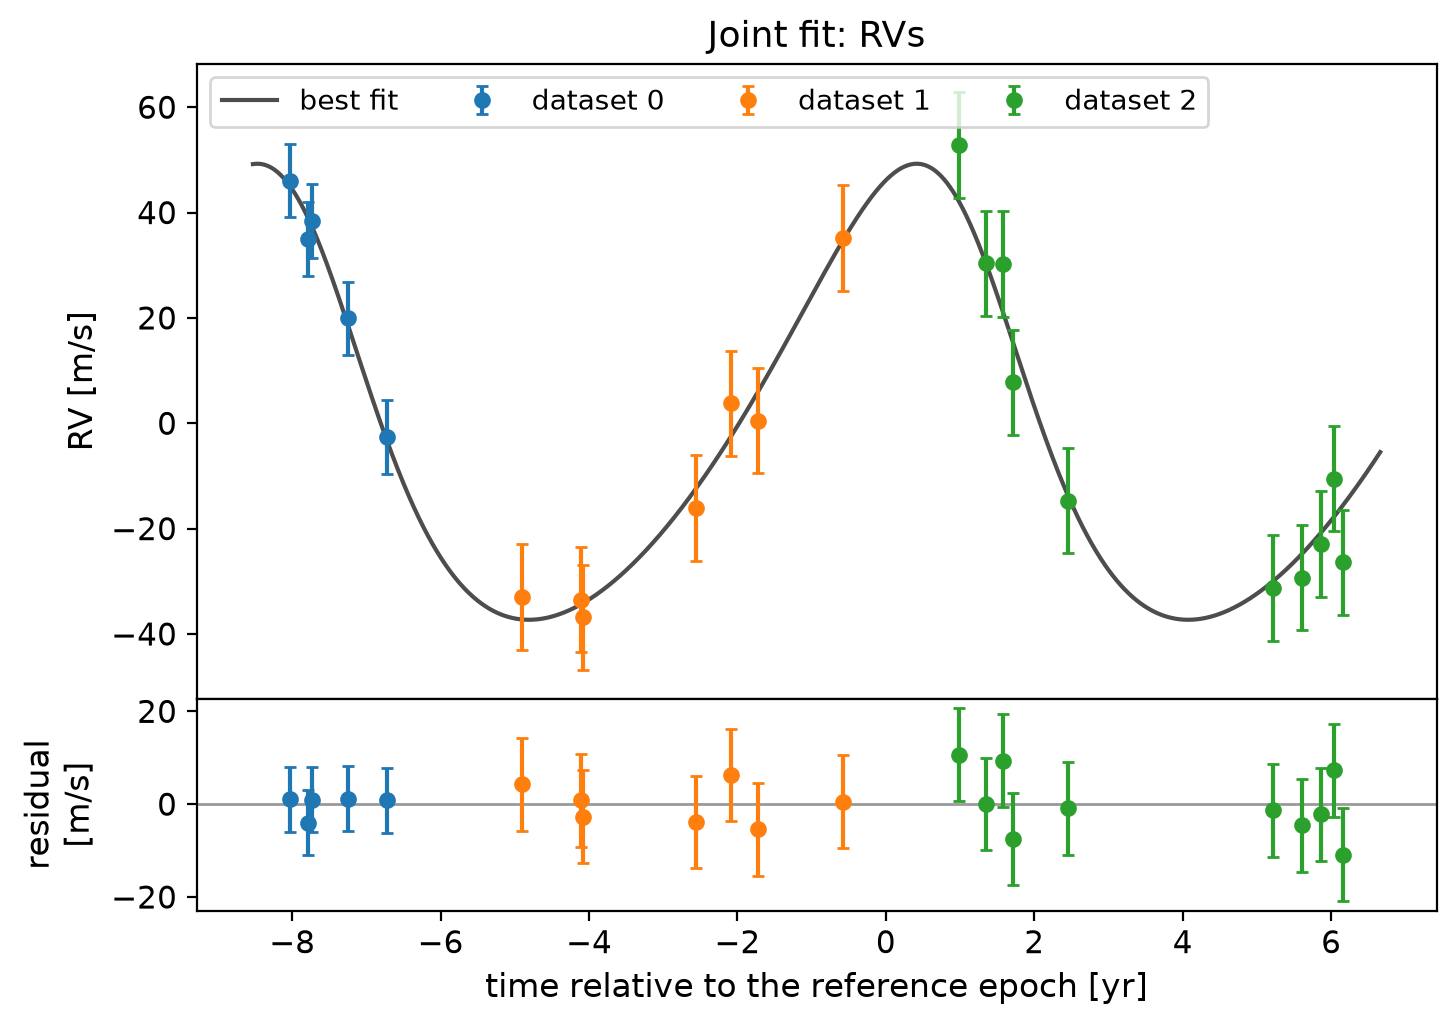

In [8]:
A, B, F, G = gmp.get_thiele_innes(fit['a0_mas'], fit['Omega'], fit['inc'], fit['w'])
fig, ax = plt.subplots(figsize=(6, 5))
gaiamock.plot_2d_orbit_and_residuals(*ast_data, period=fit['period'], ecc=fit['ecc'], Tp=fit['Tp'],
                                     delta_ra=res_joint['ra_off'], delta_dec=res_joint['dec_off'], parallax=res_joint['parallax'],
                                     pmra=res_joint['pmra'], pmdec=res_joint['pmdec'], A=A, B=B, F=F, G=G,
                                     data_release='dr5', c_funcs=c_funcs, ax=ax)
ax.set_aspect('equal', adjustable='datalim')
ax.set_xlabel(r'$\Delta\alpha\cos\delta$ [mas]', fontsize=13)
ax.set_ylabel(r'$\Delta\delta$ [mas]', fontsize=13)
ax.set_title('Photocenter orbit (joint best fit)', fontsize=13)
plt.show()

plot_rvs(res_joint, 'Joint fit: RVs')

### MCMC for the joint fit

`log_likelihood_astrometry_and_rv_planets` takes the physical parameters ordered like `res_joint['theta']` (position offsets, parallax, proper motion, then $P$, $e$, $\phi_p$, $\Omega$, $i$, $\omega$, $a_0$, then the systemic velocities), followed by the jitter of each RV dataset and, as in notebook 01, an astrometric jitter (`fit_ast_jitter=True`), started at the value that makes the best fit's astrometric reduced $\chi^2$ 1. The priors are uniform, with $0 \le i \le \pi$ and $a_0 > 0$ (other values describe the same orbits), and the astrometric jitter below 0.5 mas; $\Omega$, $\omega$ and $\phi_p$ are left unbounded. At this modest eccentricity, $\phi_p$ and $\omega$ are individually less well constrained than their combination (the orbital phase), so they have the longest autocorrelation times, about twice those of the other parameters.

In [9]:
def log_prior_joint(theta):
    plx, P, e, inc, a0, jit, s = theta[2], theta[5], theta[6], theta[9], theta[11], theta[15:18], theta[18]
    if 0 < plx and 10 < P < 1e4 and 0 <= e < 1 and 0 <= inc <= np.pi and 0 < a0 and np.all((0 <= jit) & (jit < 0.05)) and 0 <= s < 0.5:
        return 0.0
    return -np.inf

def log_prob_joint(theta):
    lp = log_prior_joint(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + gmp.log_likelihood_astrometry_and_rv_planets(theta, t_ast_yr, psi, plx_factor, ast_obs, ast_err, *rv_data, rv_dataset=rv_dataset,
                                                            fit_ast_jitter=True)

s0 = gmp.estimate_astrometric_jitter(res_joint, ast_err)
print(f'starting astrometric jitter: {1e3*s0:.1f} microarcsec')
nwalkers, nsteps = 40, 65000
p0 = gmp.initial_walkers(res_joint, nwalkers, log_prob=log_prior_joint, ast_jitter=s0, rng=rng)
np.random.seed(6)
sampler_joint = emcee.EnsembleSampler(nwalkers, p0.shape[1], log_prob_joint)
sampler_joint.run_mcmc(p0, nsteps, progress=True);

starting astrometric jitter: 17.6 microarcsec


autocorrelation times [steps]: ra_off 740, dec_off 794, parallax 529, pmra 614, pmdec 562, period_0 662, ecc_0 841, phi_p_0 1286, Omega_0 621, inc_0 541, w_0 1258, a0_mas_0 609, gamma_0 684, gamma_1 564, gamma_2 684, jitter_0 970, jitter_1 818, jitter_2 717, ast_jitter 566
chain length / longest autocorrelation time = 51
3640 samples


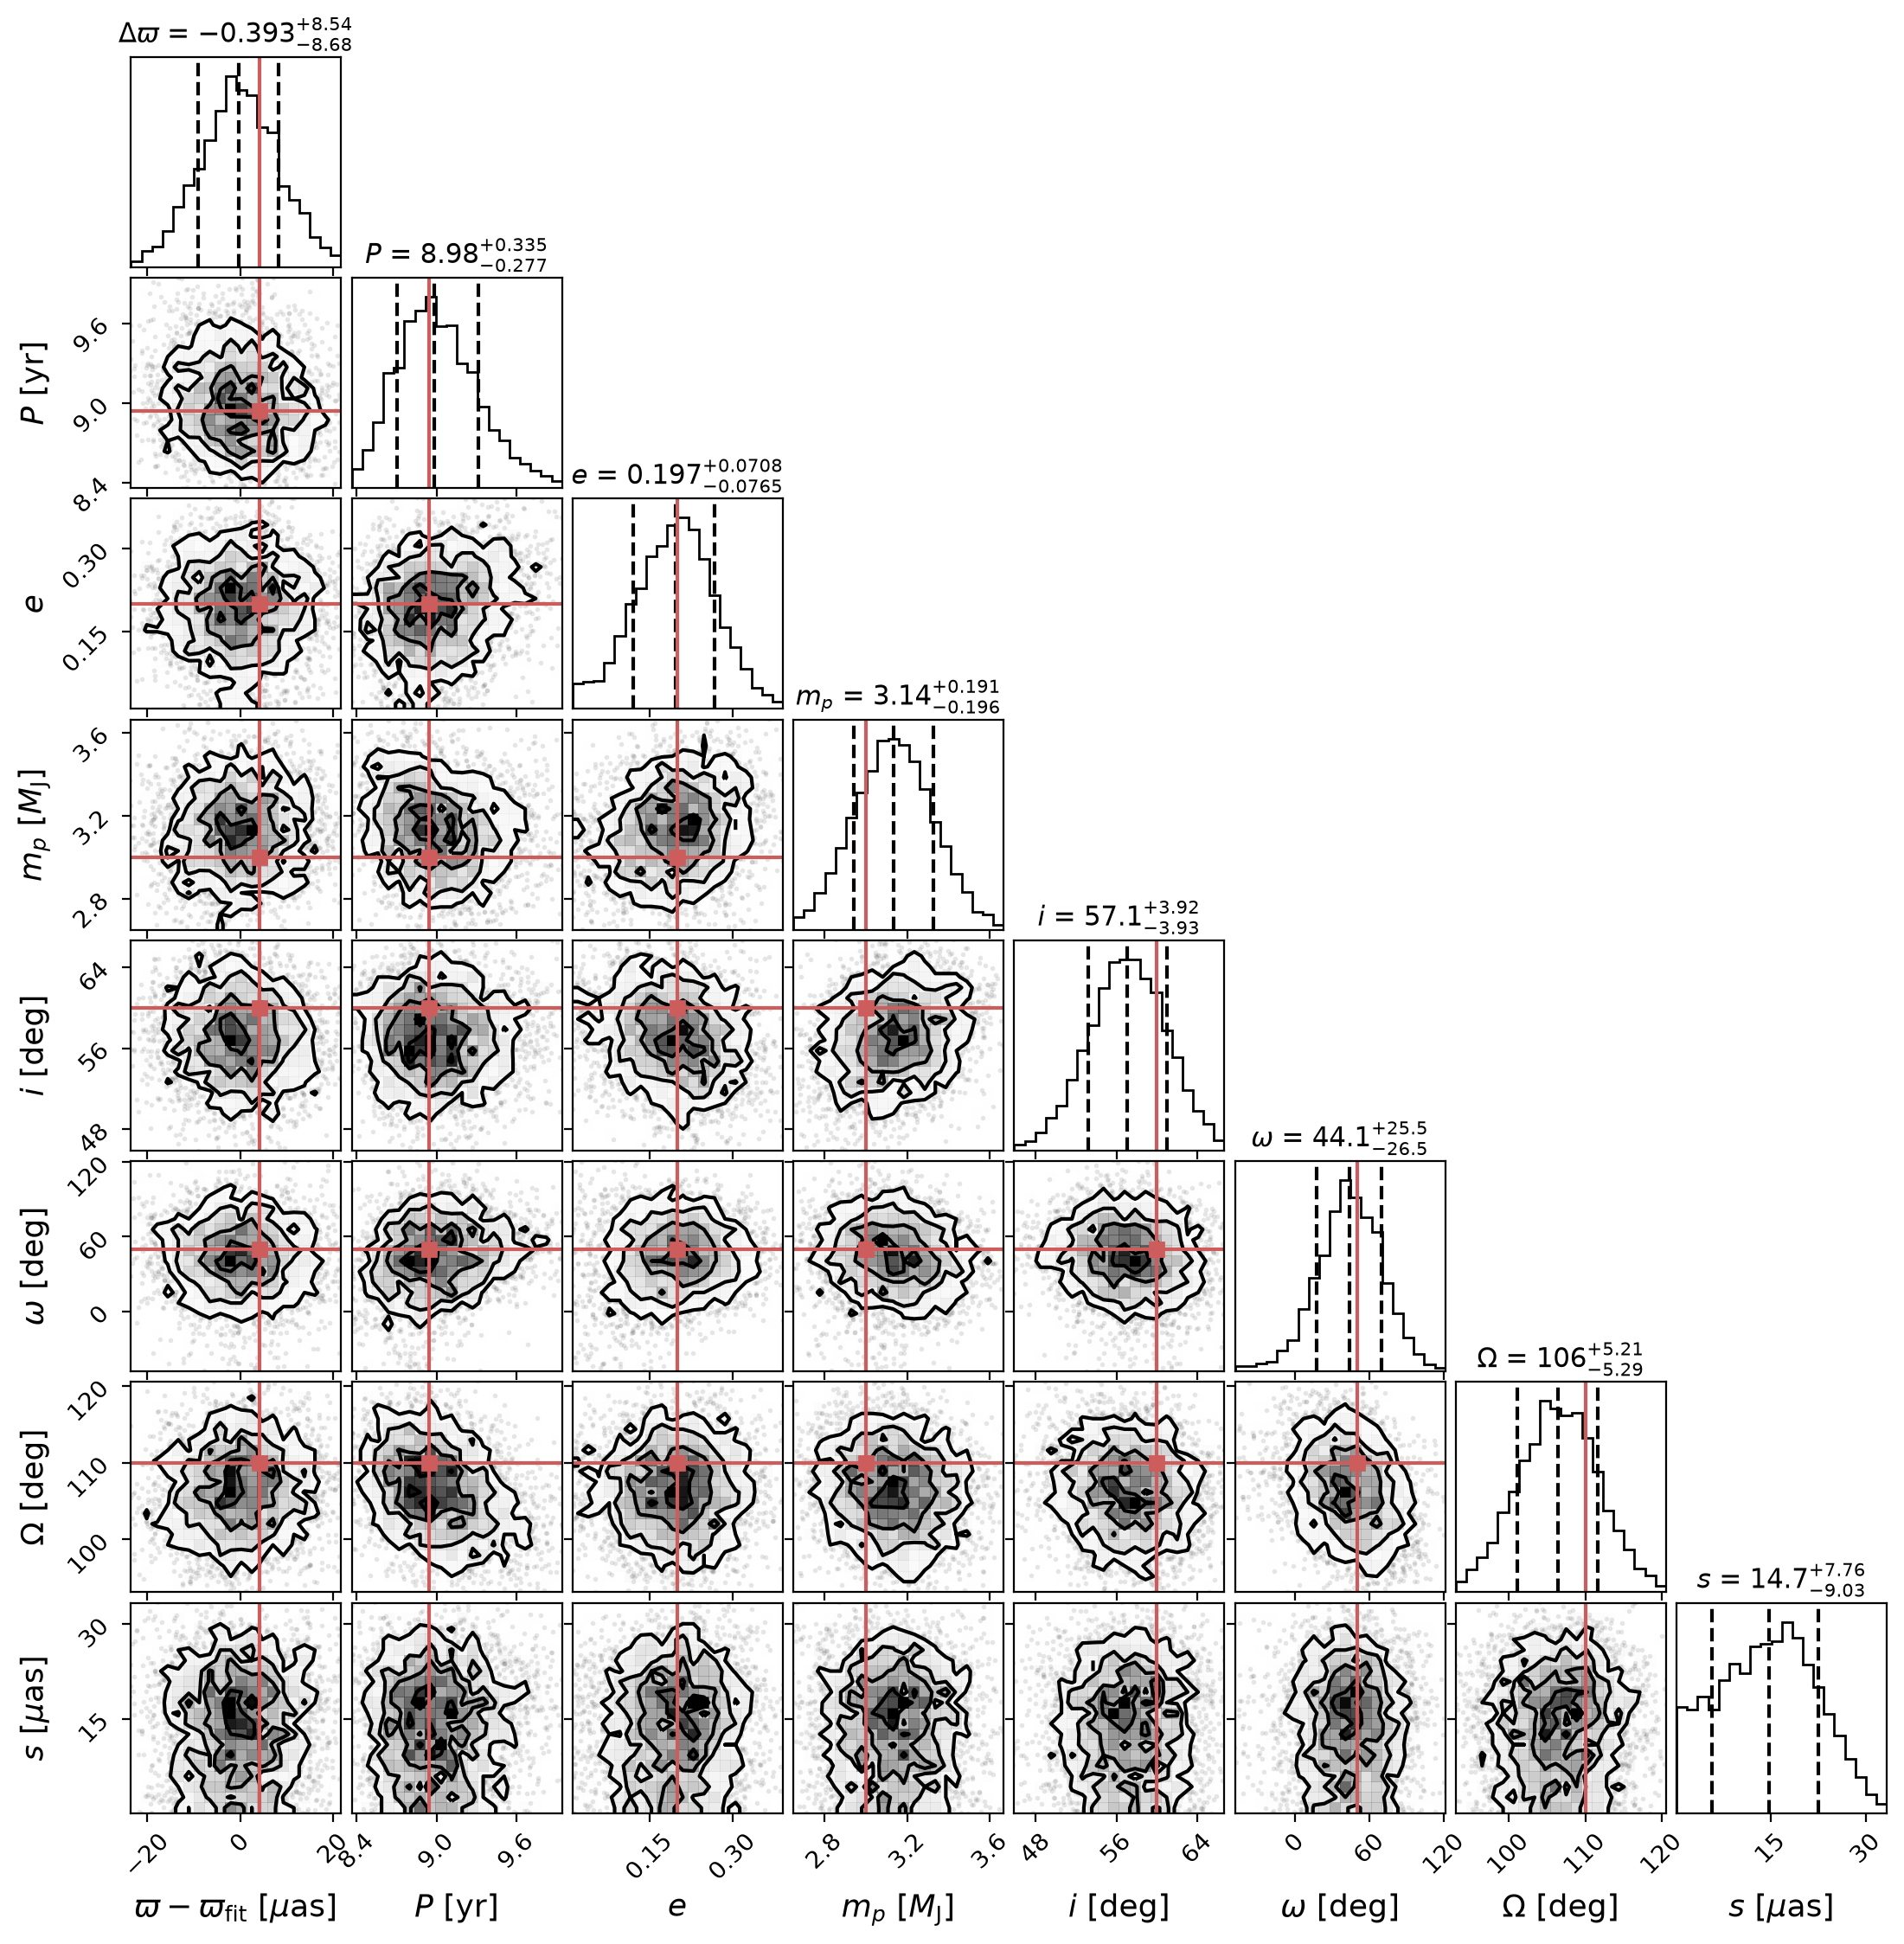

In [10]:
names_joint = res_joint['theta_names'] + ['jitter_0', 'jitter_1', 'jitter_2', 'ast_jitter']
tau = sampler_joint.get_autocorr_time(tol=0)
print('autocorrelation times [steps]:', ', '.join(f'{n} {t:.0f}' for n, t in zip(names_joint, tau)))
print(f'chain length / longest autocorrelation time = {nsteps/tau.max():.0f}')
burn, thin = int(5*tau.max()), int(tau.max()/2)
samples_joint = sampler_joint.get_chain(discard=burn, thin=thin, flat=True)
print(f'{len(samples_joint)} samples')

plx_s, P_s, e_s, Omega_s, inc_s, w_s, a0_s = (samples_joint[:, k] for k in (2, 5, 6, 8, 9, 10, 11))
m_s = gmp.get_dark_companion_mass(a0_mas=a0_s, period=P_s, parallax=plx_s, m1=m_star)
w_s = fit['w'] + np.angle(np.exp(1j*(w_s - fit['w'])))              # keep the angles continuous around the best fit
Omega_s = fit['Omega'] + np.angle(np.exp(1j*(Omega_s - fit['Omega'])))

corner_joint = np.column_stack([1e3*(plx_s - res_joint['parallax']), P_s/365.25, e_s, m_s/M_JUP, np.degrees(inc_s), np.degrees(w_s), np.degrees(Omega_s),
                                1e3*samples_joint[:, -1]])
labels = [r'$\varpi - \varpi_\mathrm{fit}$ [$\mu$as]', r'$P$ [yr]', r'$e$', r'$m_p$ [$M_\mathrm{J}$]', r'$i$ [deg]', r'$\omega$ [deg]', r'$\Omega$ [deg]',
          r'$s$ [$\mu$as]']
titles = [r'$\Delta\varpi$', r'$P$', r'$e$', r'$m_p$', r'$i$', r'$\omega$', r'$\Omega$', r'$s$']
truths = [1e3*(parallax - res_joint['parallax']), planet['period']/365.25, planet['ecc'], planet['m_planet']/M_JUP, 60.0, 50.0, 110.0, None]
fig = corner.corner(corner_joint, range=[0.99]*corner_joint.shape[1], labels=labels, titles=titles, truths=truths, truth_color='indianred', quantiles=[0.16, 0.5, 0.84],
                    show_titles=True, title_fmt='.3g', max_n_ticks=3, labelpad=0.08, label_kwargs=dict(fontsize=13), title_kwargs=dict(fontsize=11))
fig.set_size_inches(11, 11)
plt.show()

In [11]:
# what the astrometry adds to the RVs
for label, s_rv, s_joint in [('P [yr]', samples_rv[:, 3]/365.25, P_s/365.25), ('e', samples_rv[:, 4], e_s)]:
    print(f'{label:16s} RVs alone {np.median(s_rv):.3f} +/- {np.std(s_rv):.3f};  joint {np.median(s_joint):.3f} +/- {np.std(s_joint):.3f}')
print(f'mass [M_Jup]     RVs alone: m sin i = {np.median(msini_s)/M_JUP:.2f} +/- {np.std(msini_s)/M_JUP:.2f};  joint: m = {np.median(m_s)/M_JUP:.2f} +/- {np.std(m_s)/M_JUP:.2f} (true {planet["m_planet"]/M_JUP:.0f})')

P [yr]           RVs alone 9.225 +/- 0.804;  joint 8.982 +/- 0.313
e                RVs alone 0.238 +/- 0.118;  joint 0.197 +/- 0.074
mass [M_Jup]     RVs alone: m sin i = 2.88 +/- 0.52;  joint: m = 3.14 +/- 0.20 (true 3)
